# Max-Entropy Stage B Diagnostics

Two questions:
1. Is the L-BFGS line search stepping outside the PSD cone?
2. Is K diverging to infinity (while staying in the interior)?

We run Stage A (PGD) on a high-noise problem to get `X_psd` near/on the PSD-completable boundary, then run an instrumented Stage B.

In [145]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from privateggm.solvers._shared import _weights, _weighted_obj
from privateggm.solvers.pgd_maxent import pgd
from problems import make_problem

In [ ]:
# --- Stage A: run PGD on high-noise problem to get X_psd on the boundary ---
prob = make_problem(d=32, noise_level='high', seed=42)
A, inds, tau = prob['A'], prob['inds'], prob['tau']

X_psd, hist_a = pgd(A, inds, tau, max_iters=2000, eps=1e-8, min_eig=1e-6)

eigs_X = np.linalg.eigvalsh(X_psd)
print(f"Stage A: {len(hist_a)} iters, final obj = {hist_a[-1]['obj']:.4f}")
print(f"min_eig(X_psd) = {eigs_X.min():.2e}   <- near 0 means boundary case")
print(f"max_eig(X_psd) = {eigs_X.max():.2e}")

Stage A: 2000 iters, final obj = 4.1067
min_eig(X_psd) = 1.00e-03   <- near 0 means boundary case
max_eig(X_psd) = 1.19e+01


In [196]:
np.linalg.eigvalsh(X_psd)

array([1.00000000e-03, 1.00000000e-03, 1.00000000e-03, 1.00000000e-03,
       1.00000000e-03, 1.00000000e-03, 1.00000000e-03, 1.00000000e-03,
       1.00000000e-03, 1.00000000e-03, 1.00000000e-03, 1.00000000e-03,
       1.00000000e-03, 1.00000000e-03, 1.00000000e-03, 1.00000000e-03,
       1.00000000e-03, 1.00000000e-03, 1.00000000e-03, 1.00000000e-03,
       1.00000000e-03, 1.00000000e-03, 1.00000000e-03, 2.69154297e-01,
       1.22275148e+00, 1.44756115e+00, 3.37638863e+00, 4.72219333e+00,
       5.41629886e+00, 8.99316703e+00, 1.02384823e+01, 1.18930423e+01])

In [197]:
def run_maxent_diagnostics(X_psd, inds, tau, lbfgs_iters=200, gtol=1e-8):
    """Instrumented Stage B (max-entropy completion dual).
    
    Diagnostic 1: counts Cholesky failures inside loss_and_grad
                  (= line search stepping outside PSD cone)
    Diagnostic 2: tracks max/min eig of K, tr(K), log det K each iteration
                  (= whether K is diverging to infinity)
    """
    d = X_psd.shape[0]
    w = _weights(tau)
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols
    mult = np.where(diag_mask, 1.0, 2.0)

    # Mutable diagnostics accumulator (shared across closures)
    diag = {
        'n_evals': 0,
        'n_infeasible': 0,
        'infeasible_norms': [],   # ||z|| at each infeasible eval
        'iters': [],              # one dict per callback invocation
    }

    def _build_K(z):
        K = np.zeros((d, d))
        K[rows, cols] = z
        K[cols, rows] = z
        return K

    def loss_and_grad(z):
        diag['n_evals'] += 1
        K = _build_K(z)
        try:
            L = np.linalg.cholesky(K)
        except np.linalg.LinAlgError:
            # K is not PSD: line search has stepped outside the cone
            diag['n_infeasible'] += 1
            diag['infeasible_norms'].append(float(np.linalg.norm(z)))
            return 1e6, np.zeros_like(z)  # Large loss, zero gradient (no update)

        logdet_K = 2.0 * np.sum(np.log(np.diag(L)))
        Sigma = np.linalg.solve(L.T, np.linalg.solve(L, np.eye(d)))
        loss = -logdet_K + np.sum(K * X_psd)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        return float(loss), grad

    def callback(z):
        K = _build_K(z)
        eigs_K = np.linalg.eigvalsh(K)
        sign, logdet_K = np.linalg.slogdet(K)

        if sign <= 0:
            print(f"  [{len(diag['iters']):3d}] WARNING: K not PSD in callback")
            return

        Sigma = np.linalg.inv(K)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        cviol = float(np.sqrt(np.mean((Sigma[rows, cols] - X_psd[rows, cols])**2)))

        entry = {
            'iter':         len(diag['iters']),
            'n_evals':      diag['n_evals'],
            'n_infeasible': diag['n_infeasible'],
            'dual_loss':    float(-logdet_K + np.sum(K * X_psd)),
            'logdet_K':     float(logdet_K),
            'tr_K':         float(eigs_K.sum()),
            'max_eig_K':    float(eigs_K.max()),
            'min_eig_K':    float(eigs_K.min()),
            'grad_norm':    float(np.linalg.norm(grad)),
            'cviol':        cviol,
            'obj':          float(_weighted_obj(Sigma, A, inds, w)),
        }
        diag['iters'].append(entry)

        print(
            f"  [{entry['iter']:3d}] "
            f"max_eig(K)={entry['max_eig_K']:9.2e}  "
            f"min_eig(K)={entry['min_eig_K']:9.2e}  "
            f"tr(K)={entry['tr_K']:9.2e}  "
            f"logdet={entry['logdet_K']:8.2f}  "
            f"|grad|={entry['grad_norm']:8.2e}  "
            f"cviol={entry['cviol']:8.2e}  "
            f"infeas={diag['n_infeasible']}/{diag['n_evals']}"
        )

    z0 = np.where(diag_mask, 1.0 / np.maximum(X_psd[rows, cols], 1e-6), 0.0)
    K0 = _build_K(z0)
    eigs_K0 = np.linalg.eigvalsh(K0)
    print(f"Initial K: min_eig={eigs_K0.min():.2e}, max_eig={eigs_K0.max():.2e}, tr={eigs_K0.sum():.2e}")
    print()
    print(f"  {'iter':>3}   {'max_eig(K)':>12}  {'min_eig(K)':>12}  {'tr(K)':>10}  "
          f"{'logdet':>8}  {'|grad|':>10}  {'cviol':>10}  {'infeas':>8}")
    print(f"  {'-'*100}")

    result = minimize(
        loss_and_grad, z0,
        method='L-BFGS-B', jac=True,
        callback=callback,
        options={'maxiter': lbfgs_iters, 'ftol': 1e-30, 'gtol': gtol, 'maxcor': 100},
    )

    print()
    print(f"Result: {result.message}")
    print(f"Total evals: {diag['n_evals']}  |  Infeasible (non-PSD K): {diag['n_infeasible']}")
    if diag['infeasible_norms']:
        print(f"||z|| at infeasible evals: min={min(diag['infeasible_norms']):.2e}, "
              f"max={max(diag['infeasible_norms']):.2e}")

    return result, diag

In [198]:
lam = 0.00
d = X_psd.shape[0]
result, diag = run_maxent_diagnostics(X_psd + lam * np.eye(d), inds, tau, lbfgs_iters=2000)

Initial K: min_eig=3.12e-01, max_eig=2.35e+00, tr=2.55e+01

  iter     max_eig(K)    min_eig(K)       tr(K)    logdet      |grad|       cviol    infeas
  ----------------------------------------------------------------------------------------------------
  [  0] max_eig(K)= 2.35e+00  min_eig(K)= 9.31e-02  tr(K)= 2.55e+01  logdet=  -13.84  |grad|=9.52e+00  cviol=5.69e-01  infeas=0/2
  [  1] max_eig(K)= 2.36e+00  min_eig(K)= 5.59e-02  tr(K)= 2.60e+01  logdet=  -15.12  |grad|=1.29e+01  cviol=8.20e-01  infeas=2/8
  [  2] max_eig(K)= 2.38e+00  min_eig(K)= 8.13e-02  tr(K)= 2.66e+01  logdet=  -14.31  |grad|=7.86e+00  cviol=5.47e-01  infeas=3/11
  [  3] max_eig(K)= 2.40e+00  min_eig(K)= 5.91e-02  tr(K)= 2.78e+01  logdet=  -14.14  |grad|=1.08e+01  cviol=7.19e-01  infeas=3/12
  [  4] max_eig(K)= 2.52e+00  min_eig(K)= 7.54e-02  tr(K)= 3.14e+01  logdet=  -10.80  |grad|=1.08e+01  cviol=6.79e-01  infeas=3/13
  [  5] max_eig(K)= 2.66e+00  min_eig(K)= 1.22e-01  tr(K)= 3.46e+01  logdet=   -7.07  |grad|

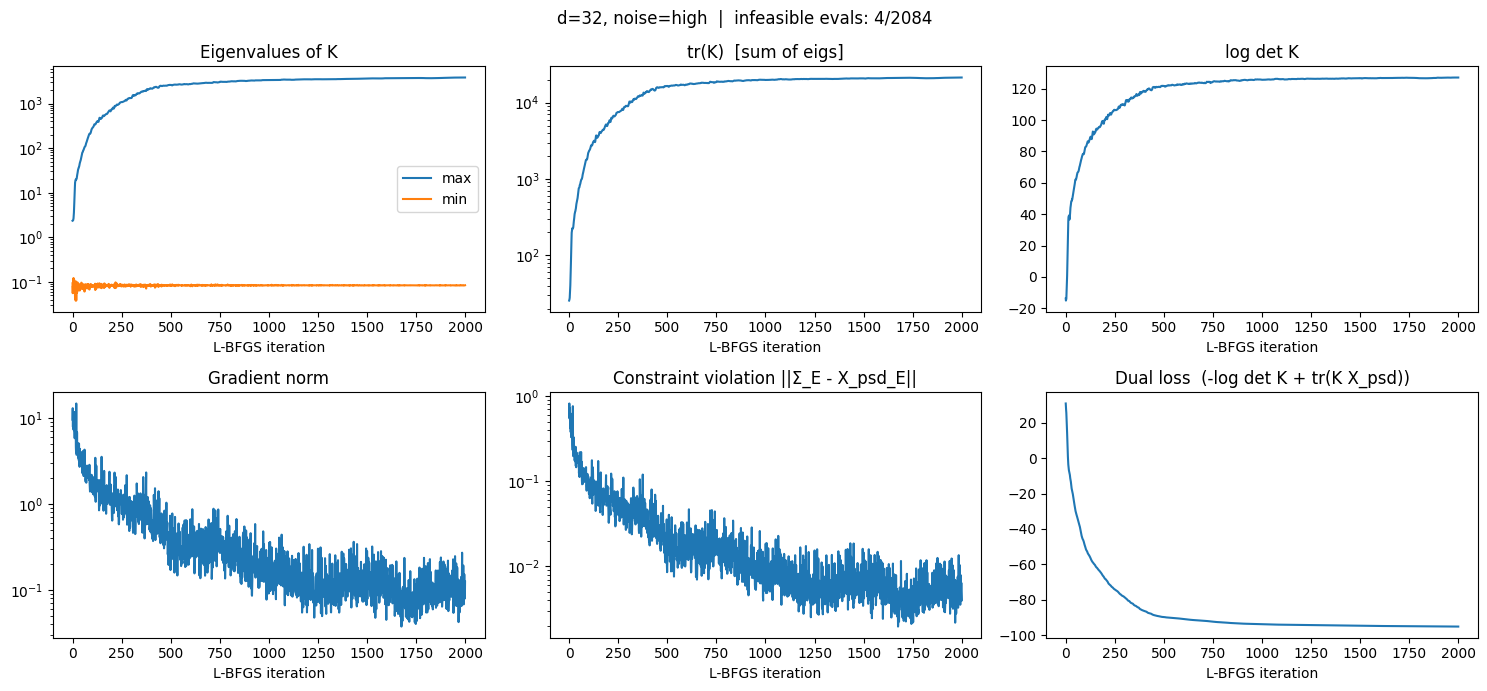

In [199]:
# --- Plots ---
its = diag['iters']
if not its:
    print("No iterations recorded.")
else:
    xs = [e['iter'] for e in its]

    fig, axes = plt.subplots(2, 3, figsize=(15, 7))

    ax = axes[0, 0]
    ax.semilogy(xs, [e['max_eig_K'] for e in its], label='max')
    ax.semilogy(xs, [e['min_eig_K'] for e in its], label='min')
    ax.set_title('Eigenvalues of K')
    ax.set_xlabel('L-BFGS iteration')
    ax.legend()

    ax = axes[0, 1]
    ax.semilogy(xs, [e['tr_K'] for e in its])
    ax.set_title('tr(K)  [sum of eigs]')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[0, 2]
    ax.plot(xs, [e['logdet_K'] for e in its])
    ax.set_title('log det K')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[1, 0]
    ax.semilogy(xs, [e['grad_norm'] for e in its])
    ax.set_title('Gradient norm')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[1, 1]
    ax.semilogy(xs, [e['cviol'] for e in its])
    ax.set_title('Constraint violation ||Σ_E - X_psd_E||')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[1, 2]
    ax.plot(xs, [e['dual_loss'] for e in its])
    ax.set_title('Dual loss  (-log det K + tr(K X_psd))')
    ax.set_xlabel('L-BFGS iteration')

    plt.suptitle(f'd=32, noise=high  |  infeasible evals: {diag["n_infeasible"]}/{diag["n_evals"]}')
    plt.tight_layout()
    plt.show()

In [136]:
# --- Compare low vs high noise side by side ---
# Useful to confirm that low-noise (interior) converges fine but high-noise diverges

for noise in ['low', 'med', 'high']:
    prob2 = make_problem(d=32, noise_level=noise, seed=42)
    X2, _ = pgd(prob2['A'], prob2['inds'], prob2['tau'], max_iters=2000, eps=1e-8)
    eigs2 = np.linalg.eigvalsh(X2)
    print(f"noise={noise}: min_eig(X_psd)={eigs2.min():.2e}")

noise=low: min_eig(X_psd)=1.81e-01
noise=med: min_eig(X_psd)=1.00e-08
noise=high: min_eig(X_psd)=1.00e-08


## Preconditioned Stage B (Dahl, Roychowdhury, Vandenberghe)

Minimize $g(u) = f(hu)$ where $z = hu$ and $h = \sqrt{H}$, with $H_e$ the diagonal of the Hessian of $-\log\det K$ evaluated at $\bar\Sigma = K^{-1}$:

$$H_e = \begin{cases} \bar\Sigma_{ii}^2 & e = (i,i) \text{ (diagonal)} \\ 4(\bar\Sigma_{ii}\bar\Sigma_{jj} + \bar\Sigma_{ij}^2) & e = (i,j),\; i\neq j \end{cases}$$

(Factor of 4 for off-diagonal comes from $\text{mult}^2 = 2^2$.) Chain rule gives $dg/du = h \cdot df/dz$. $\bar\Sigma$ is fixed at the start using $X_\text{psd}$.

**Note:** Since the optimum is on the PSD-completable boundary, $K \to \infty$ in some directions is expected — that's the correct behavior. The question is whether the *other* directions converge, especially whether $\Sigma_E \to X_\text{psd,E}$ (constraint violation $\to 0$).

In [177]:
def run_maxent_preconditioned(X_psd, inds, tau, lbfgs_iters=200, gtol=1e-8, Sigma_bar=None):
    """Stage B with diagonal preconditioner from Dahl et al.

    Minimizes g(u) = f(h * u) where z = h * u and h = sqrt(H),
    H_e = diagonal of Hessian of -log det K at Sigma_bar = K^{-1}.
    """
    d = X_psd.shape[0]
    w = _weights(tau)
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols
    mult = np.where(diag_mask, 1.0, 2.0)

    if Sigma_bar is None:
        Sigma_bar = X_psd

    # Hessian diagonal at Sigma_bar
    # Off-diagonal e=(i,j): mult=2, H_e = 2^2 * (Sii*Sjj + Sij^2)
    # Diagonal    e=(i,i): mult=1, H_e = 1^1 * Sii^2
    H = 2 * (Sigma_bar[rows, rows] * Sigma_bar[cols, cols]
                   + Sigma_bar[rows, cols] * Sigma_bar[cols, rows])
    h = np.sqrt(np.maximum(H, 1e-12))

    diag = {'n_evals': 0, 'n_infeasible': 0, 'iters': []}

    def _build_K(z):
        K = np.zeros((d, d))
        K[rows, cols] = z
        K[cols, rows] = z
        return K

    def loss_and_grad(u):
        diag['n_evals'] += 1
        z = h * u
        K = _build_K(z)
        try:
            L = np.linalg.cholesky(K)
        except np.linalg.LinAlgError:
            diag['n_infeasible'] += 1
            shift = -np.linalg.eigvalsh(K).min() + 1e-4
            Sigma_reg = np.linalg.inv(K + shift * np.eye(d))
            grad_z = mult * (X_psd[rows, cols] - Sigma_reg[rows, cols])
            return 1e6, h * grad_z

        logdet_K = 2.0 * np.sum(np.log(np.diag(L)))
        Sigma = np.linalg.solve(L.T, np.linalg.solve(L, np.eye(d)))
        loss = -logdet_K + np.sum(K * X_psd)
        grad_z = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        return float(loss), h * grad_z  # chain rule

    def callback(u):
        z = h * u
        K = _build_K(z)
        eigs_K = np.linalg.eigvalsh(K)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return
        Sigma = np.linalg.inv(K)
        grad_z = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        cviol = float(np.sqrt(np.mean((Sigma[rows, cols] - X_psd[rows, cols])**2)))

        entry = {
            'iter':         len(diag['iters']),
            'n_infeasible': diag['n_infeasible'],
            'dual_loss':    float(-logdet_K + np.sum(K * X_psd)),
            'logdet_K':     float(logdet_K),
            'tr_K':         float(eigs_K.sum()),
            'max_eig_K':    float(eigs_K.max()),
            'min_eig_K':    float(eigs_K.min()),
            'grad_norm':    float(np.linalg.norm(grad_z)),
            'cviol':        cviol,
        }
        diag['iters'].append(entry)
        print(
            f"  [{entry['iter']:3d}] "
            f"max_eig(K)={entry['max_eig_K']:9.2e}  "
            f"min_eig(K)={entry['min_eig_K']:9.2e}  "
            f"tr(K)={entry['tr_K']:9.2e}  "
            f"logdet={entry['logdet_K']:8.2f}  "
            f"|grad|={entry['grad_norm']:8.2e}  "
            f"cviol={entry['cviol']:8.2e}  "
            f"infeas={diag['n_infeasible']}/{diag['n_evals']}"
        )

    z0 = np.where(diag_mask, 1.0 / np.maximum(X_psd[rows, cols], 1e-6), 0.0)
    u0 = z0 / h
    K0 = _build_K(z0)
    eigs_K0 = np.linalg.eigvalsh(K0)
    print(f"Preconditioner H range: [{H.min():.2e}, {H.max():.2e}]  "
          f"(sqrt condition: {np.sqrt(H.max()/H.min()):.2e})")
    print(f"Initial K: min_eig={eigs_K0.min():.2e}, max_eig={eigs_K0.max():.2e}")
    print()

    result = minimize(
        loss_and_grad, u0,
        method='L-BFGS-B', jac=True,
        callback=callback,
        options={'maxiter': lbfgs_iters, 'ftol': 1e-30, 'gtol': gtol, 'maxcor': 100},
    )

    print(f"\nResult: {result.message}")
    print(f"Total evals: {diag['n_evals']}  |  Infeasible: {diag['n_infeasible']}")
    return result, diag

In [178]:
# Run preconditioned version on the raw X_psd (no lambda shift)
# and compare to unpreconditioned with lambda=0.1
result_pre, diag_pre = run_maxent_preconditioned(X_psd, inds, tau, lbfgs_iters=2000)

Preconditioner H range: [6.36e-01, 4.10e+01]  (sqrt condition: 8.03e+00)
Initial K: min_eig=3.12e-01, max_eig=2.34e+00

  [  0] max_eig(K)= 2.34e+00  min_eig(K)= 1.50e-01  tr(K)= 2.54e+01  logdet=  -11.62  |grad|=1.17e+01  cviol=5.45e-01  infeas=2/8
  [  1] max_eig(K)= 2.34e+00  min_eig(K)= 6.41e-02  tr(K)= 2.59e+01  logdet=  -13.63  |grad|=1.37e+01  cviol=8.18e-01  infeas=4/14
  [  2] max_eig(K)= 2.34e+00  min_eig(K)= 7.61e-02  tr(K)= 2.64e+01  logdet=  -13.37  |grad|=1.09e+01  cviol=6.53e-01  infeas=4/16
  [  3] max_eig(K)= 2.34e+00  min_eig(K)= 2.95e-02  tr(K)= 2.83e+01  logdet=  -13.84  |grad|=2.70e+01  cviol=1.54e+00  infeas=4/17
  [  4] max_eig(K)= 2.35e+00  min_eig(K)= 1.13e-01  tr(K)= 3.07e+01  logdet=   -8.93  |grad|=7.83e+00  cviol=4.80e-01  infeas=4/18
  [  5] max_eig(K)= 2.35e+00  min_eig(K)= 1.04e-01  tr(K)= 3.13e+01  logdet=   -9.07  |grad|=7.88e+00  cviol=5.10e-01  infeas=4/19
  [  6] max_eig(K)= 2.42e+00  min_eig(K)= 6.68e-02  tr(K)= 3.42e+01  logdet=   -8.52  |grad|=9.

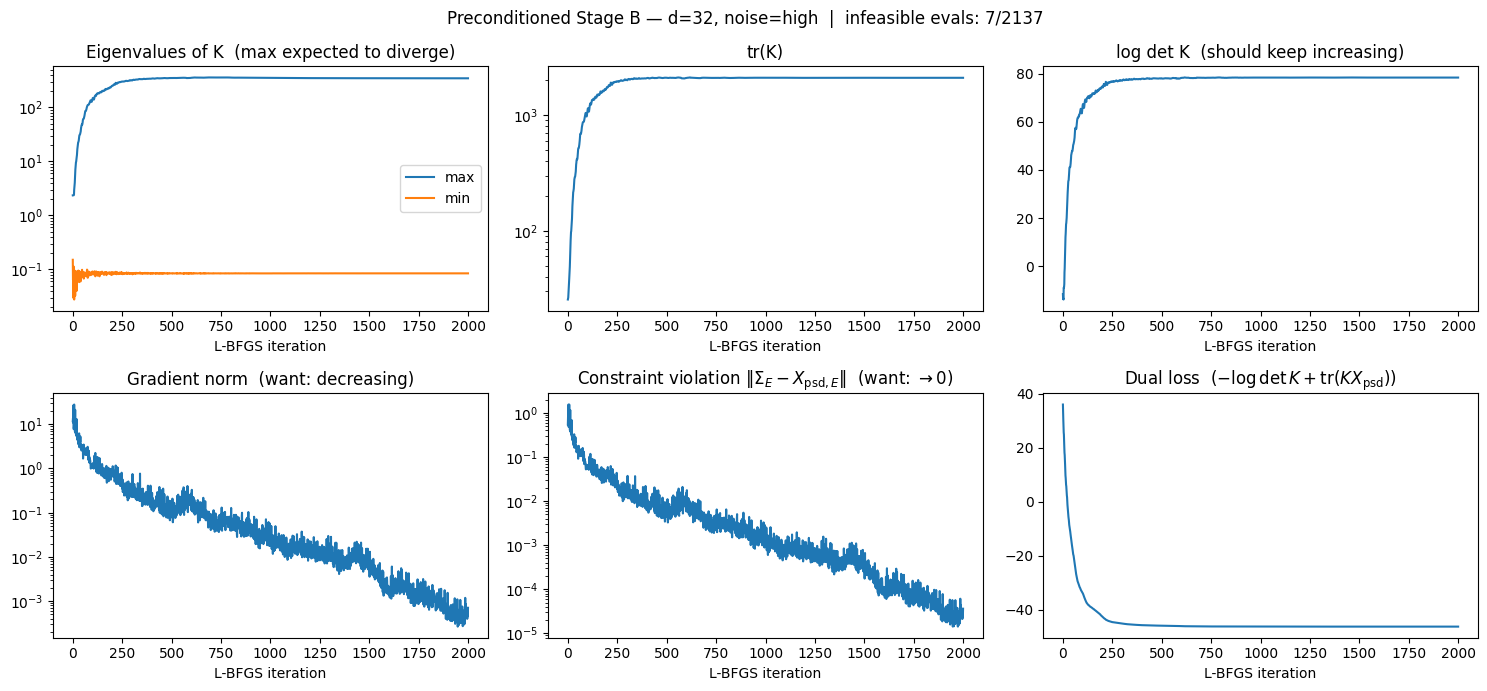

In [179]:
its = diag_pre['iters']
if not its:
    print("No iterations recorded.")
else:
    xs = [e['iter'] for e in its]

    fig, axes = plt.subplots(2, 3, figsize=(15, 7))

    # Top row: K trajectory (expected to diverge — that's fine)
    ax = axes[0, 0]
    ax.semilogy(xs, [e['max_eig_K'] for e in its], label='max')
    ax.semilogy(xs, [e['min_eig_K'] for e in its], label='min')
    ax.set_title('Eigenvalues of K  (max expected to diverge)')
    ax.set_xlabel('L-BFGS iteration')
    ax.legend()

    ax = axes[0, 1]
    ax.semilogy(xs, [e['tr_K'] for e in its])
    ax.set_title('tr(K)')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[0, 2]
    ax.plot(xs, [e['logdet_K'] for e in its])
    ax.set_title('log det K  (should keep increasing)')
    ax.set_xlabel('L-BFGS iteration')

    # Bottom row: convergence of the "good" directions
    ax = axes[1, 0]
    ax.semilogy(xs, [e['grad_norm'] for e in its])
    ax.set_title('Gradient norm  (want: decreasing)')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[1, 1]
    ax.semilogy(xs, [e['cviol'] for e in its])
    ax.set_title('Constraint violation $\\|\\Sigma_E - X_{\\mathrm{psd},E}\\|$  (want: $\\to 0$)')
    ax.set_xlabel('L-BFGS iteration')

    ax = axes[1, 2]
    ax.plot(xs, [e['dual_loss'] for e in its])
    ax.set_title('Dual loss  ($-\\log\\det K + \\mathrm{tr}(K X_\\mathrm{psd})$)')
    ax.set_xlabel('L-BFGS iteration')

    plt.suptitle(
        f'Preconditioned Stage B — d=32, noise=high  |  '
        f'infeasible evals: {diag_pre["n_infeasible"]}/{diag_pre["n_evals"]}'
    )
    plt.tight_layout()
    plt.show()

## Box-constrained Stage B

L-BFGS-B supports bounds natively. When a variable hits its bound, L-BFGS-B projects it out of the active subspace and accumulates curvature only for the remaining variables. So once the diverging $K$ entries hit their upper bound $M$, they become inactive and the optimizer can converge cleanly on the bounded directions.\n\nBounds: diagonal $z_e \in [\epsilon, M]$, off-diagonal $z_e \in [-M, M]$. With $M$ large enough, bounded variables are unaffected; diverging ones hit $M$ early and are decoupled.

In [140]:
def run_maxent_boxed(X_psd, inds, tau, M=1e6, eps_diag=1e-6, lbfgs_iters=500, gtol=1e-8):
    """Stage B with box constraints on z entries of K.

    Diagonal entries: z_e in [eps_diag, M]
    Off-diagonal:     z_e in [-M, M]

    Once diverging entries hit M they are projected out of the L-BFGS-B active
    subspace, decoupling them from the bounded directions.
    """
    d = X_psd.shape[0]
    w = _weights(tau)
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols
    mult = np.where(diag_mask, 1.0, 2.0)

    bounds = [(eps_diag, M) if dm else (-M, M) for dm in diag_mask]

    diag = {'n_evals': 0, 'n_infeasible': 0, 'iters': [], 'n_active_bound': []}

    def _build_K(z):
        K = np.zeros((d, d))
        K[rows, cols] = z
        K[cols, rows] = z
        return K

    def loss_and_grad(z):
        diag['n_evals'] += 1
        K = _build_K(z)
        try:
            L = np.linalg.cholesky(K)
        except np.linalg.LinAlgError:
            diag['n_infeasible'] += 1
            shift = -np.linalg.eigvalsh(K).min() + 1e-4
            Sigma_reg = np.linalg.inv(K + shift * np.eye(d))
            grad = mult * (X_psd[rows, cols] - Sigma_reg[rows, cols])
            return 1e15, grad

        logdet_K = 2.0 * np.sum(np.log(np.diag(L)))
        Sigma = np.linalg.solve(L.T, np.linalg.solve(L, np.eye(d)))
        loss = -logdet_K + np.sum(K * X_psd)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        return float(loss), grad

    def callback(z):
        K = _build_K(z)
        eigs_K = np.linalg.eigvalsh(K)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return
        Sigma = np.linalg.inv(K)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        cviol = float(np.sqrt(np.mean((Sigma[rows, cols] - X_psd[rows, cols])**2)))

        # Count how many variables are at their upper bound (the diverging ones)
        n_at_upper = int(np.sum(z >= M * 0.999))
        diag['n_active_bound'].append(n_at_upper)

        entry = {
            'iter':         len(diag['iters']),
            'n_infeasible': diag['n_infeasible'],
            'dual_loss':    float(-logdet_K + np.sum(K * X_psd)),
            'logdet_K':     float(logdet_K),
            'tr_K':         float(eigs_K.sum()),
            'max_eig_K':    float(eigs_K.max()),
            'min_eig_K':    float(eigs_K.min()),
            'grad_norm':    float(np.linalg.norm(grad)),
            'cviol':        cviol,
            'n_at_upper':   n_at_upper,
        }
        diag['iters'].append(entry)
        print(
            f"  [{entry['iter']:3d}] "
            f"max_eig(K)={entry['max_eig_K']:9.2e}  "
            f"min_eig(K)={entry['min_eig_K']:9.2e}  "
            f"|grad|={entry['grad_norm']:8.2e}  "
            f"cviol={entry['cviol']:8.2e}  "
            f"at_bound={n_at_upper}"
        )

    z0 = np.where(diag_mask, 1.0 / np.maximum(X_psd[rows, cols], 1e-6), 0.0)
    z0 = np.clip(z0, [b[0] for b in bounds], [b[1] for b in bounds])

    print(f"M={M:.0e}  bounds: diag=[{eps_diag:.0e}, {M:.0e}], off-diag=[{-M:.0e}, {M:.0e}]")
    print()

    result = minimize(
        loss_and_grad, z0,
        method='L-BFGS-B', jac=True,
        bounds=bounds,
        callback=callback,
        options={'maxiter': lbfgs_iters, 'ftol': 0, 'gtol': gtol},
    )

    print(f"\nResult: {result.message}")
    print(f"Total evals: {diag['n_evals']}  |  Infeasible: {diag['n_infeasible']}")
    its = diag['iters']
    if its:
        print(f"Final: cviol={its[-1]['cviol']:.2e}, at_bound={its[-1]['n_at_upper']}, "
              f"max_eig(K)={its[-1]['max_eig_K']:.2e}")
    return result, diag

In [141]:
# Sweep over M to see how bound tightness affects convergence and cviol
for M in [1e3, 1e4, 1e6]:
    print(f"\n{'='*60}  M = {M:.0e}")
    result_box, diag_box = run_maxent_boxed(X_psd, inds, tau, M=M, lbfgs_iters=1000)
    print()


============================================================  M = 1e+03
M=1e+03  bounds: diag=[1e-06, 1e+03], off-diag=[-1e+03, 1e+03]

  [  0] max_eig(K)= 2.30e+00  min_eig(K)= 1.14e-01  |grad|=8.72e+00  cviol=4.87e-01  at_bound=0
  [  1] max_eig(K)= 2.31e+00  min_eig(K)= 5.19e-02  |grad|=1.40e+01  cviol=8.72e-01  at_bound=0
  [  2] max_eig(K)= 2.33e+00  min_eig(K)= 5.99e-02  |grad|=1.15e+01  cviol=7.46e-01  at_bound=0
  [  3] max_eig(K)= 2.35e+00  min_eig(K)= 1.16e-01  |grad|=5.92e+00  cviol=3.86e-01  at_bound=0
  [  4] max_eig(K)= 2.41e+00  min_eig(K)= 7.09e-02  |grad|=1.04e+01  cviol=6.73e-01  at_bound=0
  [  5] max_eig(K)= 2.60e+00  min_eig(K)= 4.15e-02  |grad|=1.68e+01  cviol=9.83e-01  at_bound=0
  [  6] max_eig(K)= 2.77e+00  min_eig(K)= 1.06e-01  |grad|=7.93e+00  cviol=4.33e-01  at_bound=0
  [  7] max_eig(K)= 2.95e+00  min_eig(K)= 1.15e-01  |grad|=7.38e+00  cviol=3.92e-01  at_bound=0
  [  8] max_eig(K)= 4.17e+00  min_eig(K)= 1.13e-01  |grad|=7.84e+00  cviol=4.11e-01  at_bound=0

Detailed run with M=1e+01
M=1e+01  bounds: diag=[1e-06, 1e+01], off-diag=[-1e+01, 1e+01]

  [  0] max_eig(K)= 2.30e+00  min_eig(K)= 1.14e-01  |grad|=8.72e+00  cviol=4.87e-01  at_bound=0
  [  1] max_eig(K)= 2.31e+00  min_eig(K)= 5.19e-02  |grad|=1.40e+01  cviol=8.72e-01  at_bound=0
  [  2] max_eig(K)= 2.33e+00  min_eig(K)= 5.99e-02  |grad|=1.15e+01  cviol=7.46e-01  at_bound=0
  [  3] max_eig(K)= 2.35e+00  min_eig(K)= 1.16e-01  |grad|=5.92e+00  cviol=3.86e-01  at_bound=0
  [  4] max_eig(K)= 2.41e+00  min_eig(K)= 7.09e-02  |grad|=1.04e+01  cviol=6.73e-01  at_bound=0
  [  5] max_eig(K)= 2.60e+00  min_eig(K)= 4.15e-02  |grad|=1.68e+01  cviol=9.83e-01  at_bound=0
  [  6] max_eig(K)= 2.77e+00  min_eig(K)= 1.06e-01  |grad|=7.93e+00  cviol=4.33e-01  at_bound=0
  [  7] max_eig(K)= 2.95e+00  min_eig(K)= 1.15e-01  |grad|=7.38e+00  cviol=3.92e-01  at_bound=0
  [  8] max_eig(K)= 4.17e+00  min_eig(K)= 1.13e-01  |grad|=7.84e+00  cviol=4.11e-01  at_bound=0
  [  9] max_eig(K)= 5.50e+00  min_eig(K)= 6.07

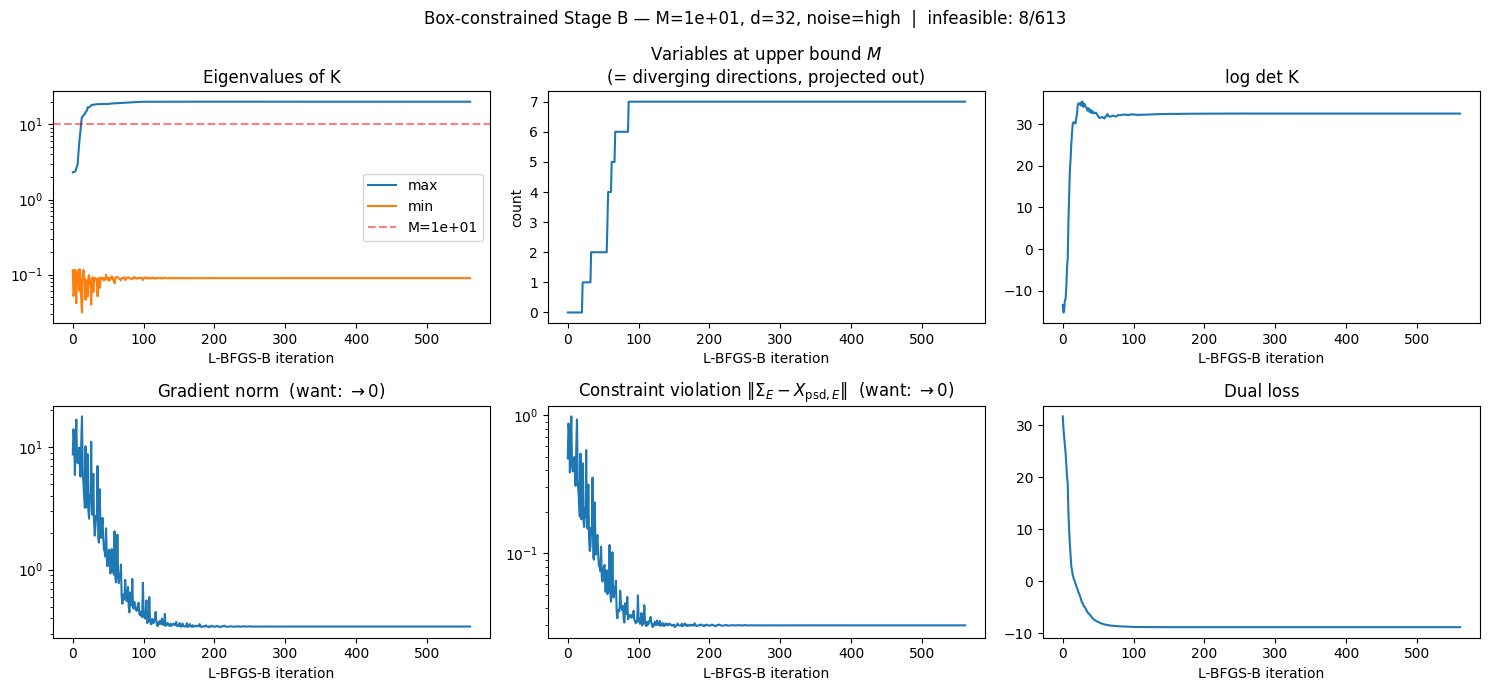

In [ ]:
# Run a single M for detailed plots (re-run with chosen M after the sweep)
M_plot = 1e2
print(f"Detailed run with M={M_plot:.0e}")
result_box, diag_box = run_maxent_boxed(X_psd, inds, tau, M=M_plot, lbfgs_iters=1000)

its = diag_box['iters']
if its:
    xs = [e['iter'] for e in its]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))

    ax = axes[0, 0]
    ax.semilogy(xs, [e['max_eig_K'] for e in its], label='max')
    ax.semilogy(xs, [e['min_eig_K'] for e in its], label='min')
    ax.axhline(M_plot, color='r', linestyle='--', alpha=0.5, label=f'M={M_plot:.0e}')
    ax.set_title('Eigenvalues of K')
    ax.set_xlabel('L-BFGS-B iteration')
    ax.legend()

    ax = axes[0, 1]
    ax.plot(xs, [e['n_at_upper'] for e in its])
    ax.set_title('Variables at upper bound $M$\n(= diverging directions, projected out)')
    ax.set_xlabel('L-BFGS-B iteration')
    ax.set_ylabel('count')

    ax = axes[0, 2]
    ax.plot(xs, [e['logdet_K'] for e in its])
    ax.set_title('log det K')
    ax.set_xlabel('L-BFGS-B iteration')

    ax = axes[1, 0]
    ax.semilogy(xs, [e['grad_norm'] for e in its])
    ax.set_title('Gradient norm  (want: $\\to 0$)')
    ax.set_xlabel('L-BFGS-B iteration')

    ax = axes[1, 1]
    ax.semilogy(xs, [e['cviol'] for e in its])
    ax.set_title('Constraint violation $\\|\\Sigma_E - X_{\\mathrm{psd},E}\\|$  (want: $\\to 0$)')
    ax.set_xlabel('L-BFGS-B iteration')

    ax = axes[1, 2]
    ax.plot(xs, [e['dual_loss'] for e in its])
    ax.set_title('Dual loss')
    ax.set_xlabel('L-BFGS-B iteration')

    plt.suptitle(
        f'Box-constrained Stage B — M={M_plot:.0e}, d=32, noise=high  |  '
        f'infeasible: {diag_box["n_infeasible"]}/{diag_box["n_evals"]}'
    )
    plt.tight_layout()
    plt.show()